# Network Science Coursework

## Import Packages

In [ ]:
from collections import defaultdict
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pickle
import polars as pl
import raphtory as rp
import scikit_posthocs as sp
import seaborn as sns
import scipy.stats as stats
import statsmodels.formula.api as smf

## Set-up

In [ ]:
folders = ["data", "figures", "metrics", "tables"]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

bin_size = 5
min_passes_per_window = 3
state_order = ["winning", "drawing", "losing"]
window_size = 300_000

## Load Data

In [ ]:
events_df = pl.read_parquet("data/events_data.parquet")
matches_df = pl.read_parquet("data/matches_data.parquet")

## Preprocessing

In [ ]:
events_df = (
    
    events_df

    .join(
        matches_df.select(["match_id", "match_date", "kick_off", "home_score", "away_score"]),
        on="match_id",
        how="left"
    )

    .with_columns(
        pl.concat_str([
            pl.col("match_date"),
            pl.lit(" "),
            pl.col("kick_off")
        ]).str.strptime(
            pl.Datetime(time_unit="us"),
            "%Y-%m-%d %H:%M:%S%.f"
        ).dt.replace_time_zone("Europe/London")
        .alias("kickoff_dt")
    )

    .with_columns(
        pl.col("timestamp")
        .str.strptime(pl.Time, "%H:%M:%S%.f")
        .cast(pl.Duration)
        .alias("ts_duration")
    )

    .with_columns(
        (
            pl.col("kickoff_dt")
            + (
                pl.when((pl.col("period") == 1) & (pl.col("type") == "Half End"))
                .then(pl.col("ts_duration"))
                .otherwise(None)
                .max()
                .over("match_id")
            )
        ).alias("first_half_end")
    )

    .with_columns(
        (
            pl.when(pl.col("period") == 2)
            .then(pl.col("first_half_end") + pl.col("ts_duration"))
            .otherwise(pl.col("kickoff_dt") + pl.col("ts_duration"))
        )
        .cast(pl.Datetime("us"))
        .alias("full_timestamp")
    )

    .filter(~pl.col("type").is_in(["Starting XI", "Half Start", "Half End"]))

    .select([
        "id", "match_id", "index", "full_timestamp", 
        "period", "team", "player", "pass_recipient",
        "type", "shot_outcome"
    ])

    .sort(["match_id", "index"])
)

events_df.head()

In [ ]:
passes_df = (
    
    events_df

    .filter((pl.col("type") == "Pass") & (pl.col("pass_recipient").is_not_null()))
    
    .select([
        "id", "match_id", "index", "full_timestamp", 
        "period", "team", "player", "pass_recipient",
        "shot_outcome"
    ])
)

passes_df.head()

## Construct Temporal Graphs

In [ ]:
graphs_dict = defaultdict(dict)

for (match_id, team), df in tqdm(
    passes_df.partition_by(["match_id", "team"], as_dict=True).items(),
    desc="Building temporal graphs"
):
    g = rp.Graph()
    g.load_edges(
        df,
        src="player",
        dst="pass_recipient",
        time="full_timestamp"
    )
    graphs_dict[match_id][team] = g

flattened_graphs_list = [v for inner in graphs_dict.values() for v in inner.values()]

with open("metrics/number_of_matches.pkl", "wb") as f:
    pickle.dump(len(graphs_dict), f)

with open("metrics/number_of_graphs.pkl", "wb") as f:
    pickle.dump(len(flattened_graphs_list), f)

## Metric Functions

In [ ]:
def edge_event_count(graph):
    count = 0
    for edge in graph.edges:
        count += sum(1 for _ in edge.history)
    return count

def out_degree_centralisation(graph):
    nodes = list(graph.nodes)
    n = len(nodes)

    if n <= 2 or graph.count_edges() == 0:
        return np.nan

    out_degrees = [node.out_degree() for node in nodes]

    max_out = max(out_degrees)
    numerator = sum(max_out - deg for deg in out_degrees)

    denominator = (n - 1) * (n - 2)

    if denominator == 0:
        return np.nan

    return numerator / denominator

def median_inter_event_time(graph):
    timestamps = []
    for edge in graph.edges:
        for et in edge.history:
            timestamps.append(et.t)
    if len(timestamps) < 2:
        return np.nan
    timestamps.sort()
    intervals = [timestamps[i+1] - timestamps[i] for i in range(len(timestamps)-1)]
    return float(np.nanmedian(intervals))


def burstiness(intervals):
    if len(intervals) < 2:
        return np.nan
    mu = np.nanmean(intervals)
    sigma = np.nanstd(intervals)
    if mu == 0:
        return np.nan
    return float((sigma - mu) / (sigma + mu))


def burstiness_from_graph(graph):
    timestamps = []
    for edge in graph.edges:
        for et in edge.history:
            timestamps.append(et.t)
    if len(timestamps) < 2:
        return np.nan
    timestamps.sort()
    intervals = [timestamps[i+1] - timestamps[i] for i in range(len(timestamps)-1)]
    return burstiness(intervals)


def temporal_correlation_coefficient(windowed_graph, rolling_window):
    snapshots = list(windowed_graph.rolling(window=rolling_window))
    if len(snapshots) < 2:
        return np.nan

    overlaps = []
    for g1, g2 in zip(snapshots[:-1], snapshots[1:]):
        edges1 = defaultdict(set)
        edges2 = defaultdict(set)

        for e in g1.edges:
            edges1[e.src.name].add(e.dst.name)
        for e in g2.edges:
            edges2[e.src.name].add(e.dst.name)

        all_nodes = set(edges1.keys()) | set(edges2.keys())
        for node in all_nodes:
            n1 = edges1[node]
            n2 = edges2[node]
            denom = np.sqrt(len(n1) * len(n2))
            if denom == 0:
                continue
            overlaps.append(len(n1 & n2) / denom)

    return float(np.nanmean(overlaps)) if overlaps else np.nan

## Datacard Plots

In [ ]:
max_k = 0
distributions = []

for G in flattened_graphs_list:
    
    degs = np.array([v.degree() for v in G.nodes])
    
    if len(degs) == 0:
        distributions.append(None)
        continue

    values, counts = np.unique(degs, return_counts=True)
    probs = counts / counts.sum()

    max_k = max(max_k, values.max())
    distributions.append((values, probs))

In [ ]:
D = np.zeros((len(flattened_graphs_list), int(max_k + 1)))

for i, dist in enumerate(distributions):
    if dist is None:
        continue
    values, probs = dist
    D[i, values] = probs

avg_dist = D.mean(axis=0)

In [ ]:
df = pd.DataFrame(D, columns=range(D.shape[1]))
df_long = df.melt(var_name="Degree", value_name="Proportion")

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_long, 
    x="Degree", y="Proportion", 
    flierprops={"marker": "+", "markersize": 5},
    color="lightblue"
)
plt.xlabel("Degree", fontweight="bold")
plt.ylabel("Proportion", fontweight="bold")
plt.ylim(-0.05, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/degree_distribution_boxplot.png", dpi=600)
plt.show()

In [ ]:
def mean_metric_over_rolling_windows(
    graph,
    metric_fn,
    window_size=window_size,
    step=None
):
    if step is None:
        windows = graph.rolling(window=window_size)
    else:
        windows = graph.rolling(window=window_size, step=step)

    values = []

    for w in windows:
        try:
            val = metric_fn(w)
        except Exception:
            val = np.nan

        values.append(val)

    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) == 0:
        return np.nan

    return np.mean(values)

In [ ]:
all_graphs_clustering_coef_list = [
    mean_metric_over_rolling_windows(
        g,
        rp.algorithms.global_clustering_coefficient,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

all_graphs_density_list = [
    mean_metric_over_rolling_windows(
        g,
        rp.algorithms.directed_graph_density,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

all_graphs_reciprocity_list = [
    mean_metric_over_rolling_windows(
        g,
        rp.algorithms.global_reciprocity,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

all_graphs_out_degree_centralisation_list = [
    mean_metric_over_rolling_windows(
        g,
        out_degree_centralisation,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

all_graphs_median_inter_time_interval_list = [
    mean_metric_over_rolling_windows(
        g,
        median_inter_event_time,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

all_graphs_burstiness_list = [
    mean_metric_over_rolling_windows(
        g,
        burstiness_from_graph,
        window_size=window_size
    )
    for g in flattened_graphs_list
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

metrics = [
    (all_graphs_clustering_coef_list, "Global Clustering Coefficient", (0, 1)),
    (all_graphs_density_list, "Density", (0, 1)),
    (all_graphs_reciprocity_list, "Reciprocity", (0, 1)),
    (all_graphs_out_degree_centralisation_list, "Out-Degree Centralisation", (0, 1)),
    (all_graphs_median_inter_time_interval_list, "Median Inter-Event Time (ms)", (0, 21000)),
    (all_graphs_burstiness_list, "Burstiness", (-1, 1)),
]

colours = [
    "steelblue",
    "coral",
    "mediumseagreen",
    "mediumpurple",
    "goldenrod",
    "darkorange",
]

for ax, (data, label, xlim), colour in zip(axes, metrics, colours):
    data = pd.Series(data).dropna()

    sns.histplot(
        data,
        stat="proportion",
        ax=ax,
        color=colour,
        bins=30
    )

    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Proportion", fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    if xlim is not None:
        ax.set_xlim(xlim)

plt.tight_layout()
plt.savefig(
    "figures/graph_metrics_distributions.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

## Measure Metrics by Match Status

In [ ]:
metric_fns = {
    "pass_count": edge_event_count,
    "density": rp.algorithms.directed_graph_density,
    "reciprocity": rp.algorithms.global_reciprocity,
    "clustering_coef": rp.algorithms.global_clustering_coefficient,
    "out_degree_centralisation": out_degree_centralisation,
    "median_inter_event_time": median_inter_event_time,
    "burstiness": burstiness_from_graph,
}

In [ ]:
def get_goal_timeline(df: pl.DataFrame, match_id: int) -> list:
    goals_df = (
        df
        .filter((pl.col("match_id") == match_id) & (pl.col("shot_outcome") == "Goal"))
        .select([
            pl.col("team"),
            pl.col("full_timestamp").dt.timestamp("ms").alias("timestamp")
        ])
        .sort("timestamp")
    )
    return goals_df.to_dicts()


def score_state_at_time(goal_timeline, team, t):
    goals_for = sum(1 for g in goal_timeline if g["timestamp"] < t and g["team"] == team)
    goals_against = sum(1 for g in goal_timeline if g["timestamp"] < t and g["team"] != team)

    if goals_for > goals_against:
        return "winning"
    if goals_for < goals_against:
        return "losing"
    return "drawing"


def window_contains_goal(goal_timeline, start, end):
    return any(start <= g["timestamp"] < end for g in goal_timeline)


def graph_time_bounds(graph):
    times = []
    for edge in graph.edges:
        times.extend([et.t for et in edge.history])
    if not times:
        return None, None
    return min(times), max(times)


goal_timelines = {
    match_id: get_goal_timeline(events_df, match_id)
    for match_id in graphs_dict.keys()
}

In [ ]:
def compute_metrics_for_window(windowed_graph):
    row = {}

    for name, fn in metric_fns.items():
        try:
            row[name] = fn(windowed_graph)
        except Exception:
            row[name] = np.nan

    return row


def build_match_state_metric_table(
    graphs_dict,
    goal_timelines,
    window_size=window_size,
    min_passes=min_passes_per_window,
):
    rows = []

    for match_id, team_graphs in tqdm(
        graphs_dict.items(),
        desc="Computing match-state windows"
    ):
        goal_timeline = goal_timelines.get(match_id, [])

        for team, graph in team_graphs.items():
            match_start, match_end = graph_time_bounds(graph)

            if match_start is None:
                continue

            for start in range(
                int(match_start),
                int(match_end - window_size + 1),
                int(window_size)
            ):
                end = start + window_size

                if window_contains_goal(
                    goal_timeline,
                    start,
                    end
                ):
                    continue

                windowed_graph = graph.window(start=start, end=end)

                pass_count = edge_event_count(windowed_graph)

                if pass_count < min_passes:
                    continue

                state = score_state_at_time(goal_timeline, team, start)

                metric_values = compute_metrics_for_window(windowed_graph)

                rows.append({
                    "match_id": match_id,
                    "team": team,
                    "window_start": start,
                    "window_end": end,
                    "window_midpoint_minute": ((start + end) / 2 - match_start) / 60_000,
                    "state": state,
                    "pass_count": pass_count,
                    **metric_values,
                })

    return pd.DataFrame(rows)


state_metrics_df = build_match_state_metric_table(
    graphs_dict,
    goal_timelines
)

state_metrics_df = build_match_state_metric_table(graphs_dict, goal_timelines)

state_metrics_df["time_bin"] = (
    np.floor(state_metrics_df["window_midpoint_minute"] / bin_size) * bin_size
)

state_metrics_df["time_bin_midpoint"] = state_metrics_df["time_bin"] + bin_size / 2

## Plot Metrics by Match Status

In [ ]:
def plot_metric_boxplot_subplots(
    df,
    metrics,
    ncols=2,
    save=True,
    filename="figures/metrics_by_match_state_boxplots.png"
):
    order = ["winning", "drawing", "losing"]

    n_metrics = len(metrics)
    nrows = math.ceil(n_metrics / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(6 * ncols, 4 * nrows)
    )

    axes = axes.flatten()

    for ax, metric in zip(axes, metrics):
        data = [
            df.loc[df["state"] == state, metric].dropna().values
            for state in order
        ]

        ax.boxplot(
            data,
            tick_labels=order,
            showfliers=False
        )

        label = metric.replace("_", " ").title()

        if metric == "median_inter_event_time":
            label = f"{label} (ms)"

        ax.set_title(label, fontweight="bold")
        ax.set_xlabel("Match state", fontweight="bold")
        ax.set_ylabel(label, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)

    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    plt.tight_layout()

    if save:
        plt.savefig(filename, dpi=600, bbox_inches="tight")

    plt.show()


metrics = [
    "density",
    "reciprocity",
    "clustering_coef",
    "out_degree_centralisation",
    "median_inter_event_time",
    "burstiness",
]

plot_metric_boxplot_subplots(
    state_metrics_df,
    metrics,
    ncols=2,
    save=True
)

In [44]:
def summarise_metric_over_time(df, metric):
    per_team_match = (
        df
        .dropna(subset=[metric, "state", "time_bin_midpoint", "match_id", "team"])
        .groupby(
            ["match_id", "team", "state", "time_bin_midpoint"],
            as_index=False
        )
        .agg(metric_value=(metric, "mean"))
    )

    summary = (
        per_team_match
        .groupby(["state", "time_bin_midpoint"], as_index=False)
        .agg(
            mean_value=("metric_value", "median"),
            n=("metric_value", "size"),
            std_value=("metric_value", "std")
        )
    )

    summary["sem"] = summary["std_value"] / np.sqrt(summary["n"])
    summary["ci95"] = 1.96 * summary["sem"]

    return summary

In [45]:
def plot_metric_subplots_over_time(
    df,
    metrics,
    ncols=2,
    use_ci=True,
    save=False,
    filename="figures/metrics_over_time_by_state.png"
):
    n_metrics = len(metrics)
    nrows = int(np.ceil(n_metrics / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(6 * ncols, 4 * nrows),
        sharex=True
    )

    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        summary = summarise_metric_over_time(df, metric)

        for state in state_order:
            state_df = (
                summary[summary["state"] == state]
                .sort_values("time_bin_midpoint")
            )

            if state_df.empty:
                continue

            x = state_df["time_bin_midpoint"].to_numpy()
            y = state_df["mean_value"].to_numpy()

            ax.plot(
                x,
                y,
                marker="o",
                linewidth=2,
                label=state.capitalize()
            )

            if use_ci:
                ci = state_df["ci95"].to_numpy()
                ax.fill_between(
                    x,
                    y - ci,
                    y + ci,
                    alpha=0.15
                )

        label = metric.replace("_", " ").title()

        if metric == "median_inter_event_time":
            label = f"{label} (ms)"

        ax.set_title(label, fontweight="bold")
        ax.set_xlabel("Match state", fontweight="bold")
        ax.set_ylabel(label, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)

    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        title="Match state",
        loc="upper center",
        ncol=3,
        bbox_to_anchor=(0.5, 1.05)
    )

    plt.tight_layout()

    if save:
        plt.savefig(filename, dpi=600, bbox_inches="tight")

    plt.show()

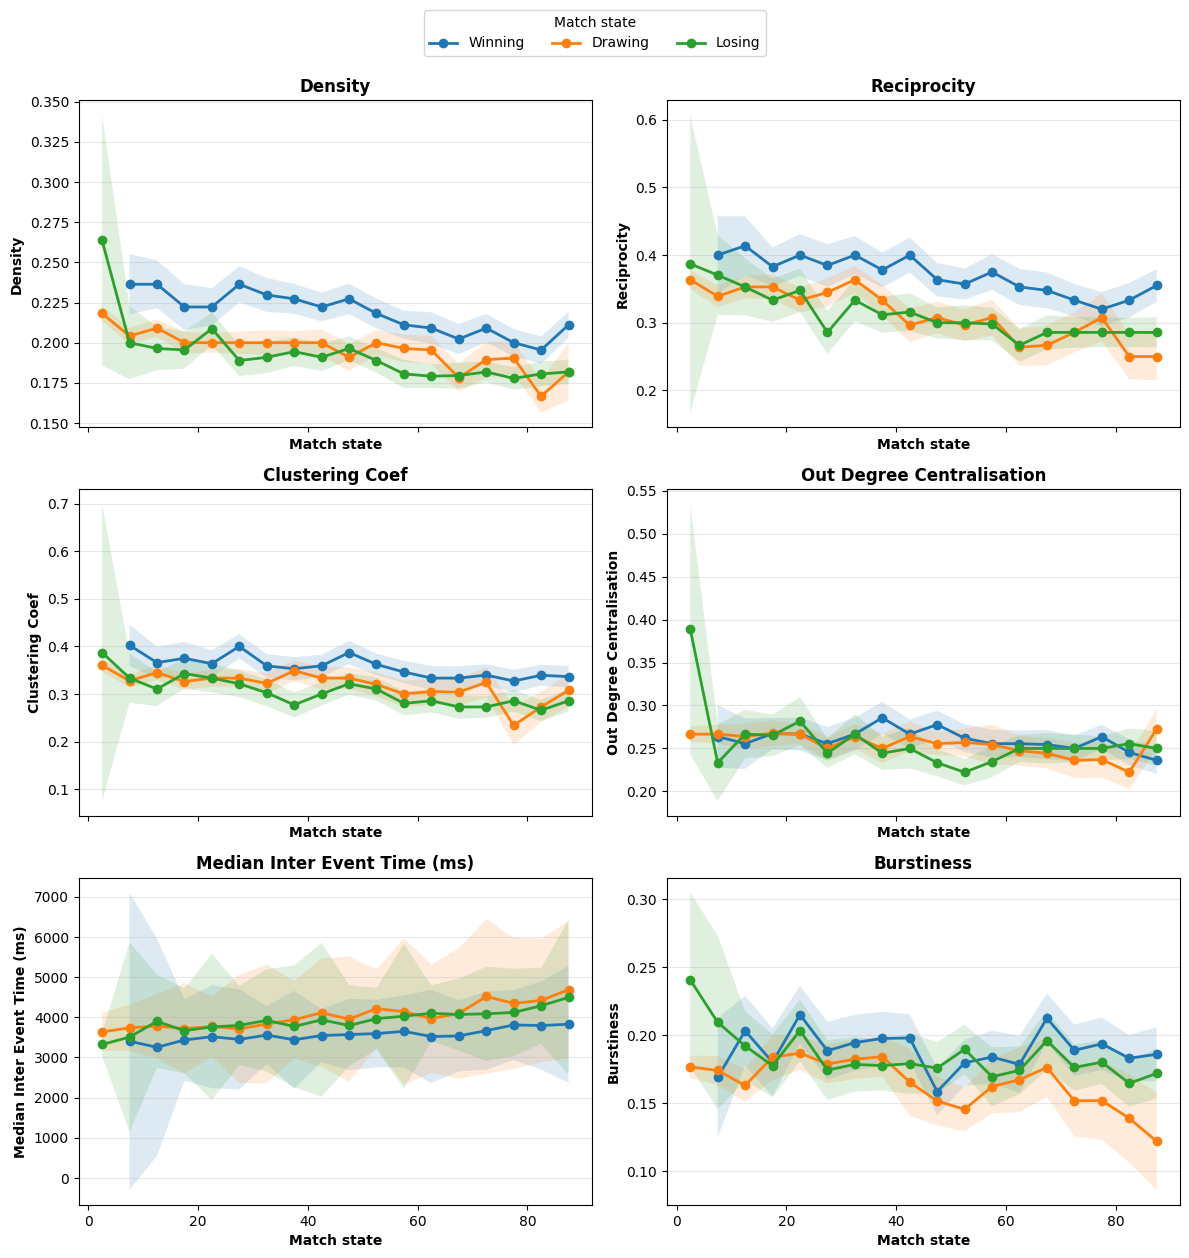

In [46]:
plot_df = state_metrics_df[
    state_metrics_df["window_midpoint_minute"].between(0, 90)
].copy()

plot_metric_subplots_over_time(
    plot_df,
    metrics,
    ncols=2,
    use_ci=True,
    save=True
)

## Significance Testing

In [ ]:
agg_df = (
    state_metrics_df
    .groupby(["match_id", "team", "state"], as_index=False)[metrics + ["pass_count"]]
    .mean()
)

In [ ]:
def cliffs_delta(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    if len(x) == 0 or len(y) == 0:
        return np.nan
    greater = 0
    less = 0
    for xi in x:
        greater += np.sum(xi > y)
        less += np.sum(xi < y)
    return float((greater - less) / (len(x) * len(y)))

def run_kruskal_tests(df, metric_cols, p_adjust="bonferroni"):
    states = ["winning", "drawing", "losing"]
    rows = []

    for metric in tqdm(metric_cols, desc="Running Kruskal-Wallis tests"):
        groups = [
            df.loc[df["state"] == state, metric].dropna().values
            for state in states
        ]

        if all(len(g) > 1 for g in groups):
            kw_stat, kw_p = stats.kruskal(*groups)
        else:
            kw_stat, kw_p = np.nan, np.nan

        rows.append({
            "Metric": metric,
            "Winning median": np.median(groups[0]) if len(groups[0]) else np.nan,
            "Drawing median": np.median(groups[1]) if len(groups[1]) else np.nan,
            "Losing median": np.median(groups[2]) if len(groups[2]) else np.nan,
            "Kruskal statistic": kw_stat,
            "Raw p-value": kw_p,
        })

    results = pd.DataFrame(rows)

    valid = results["Raw p-value"].notna()
    results["Corrected p-value"] = np.nan
    results.loc[valid, "Corrected p-value"] = multipletests(
        results.loc[valid, "Raw p-value"],
        method=p_adjust
    )[1]

    return results.sort_values(
        ["Metric", "Corrected p-value"]
    )

def run_dunn_pairwise_tests(df, metric_cols, p_adjust="bonferroni"):
    rows = []
    states = ["winning", "drawing", "losing"]
    pairs = [
        ("winning", "drawing"),
        ("winning", "losing"),
        ("drawing", "losing"),
    ]

    for metric in tqdm(metric_cols, desc="Running Dunn pairwise tests"):
        metric_df = df[["state", metric]].dropna().copy()

        metric_df["state"] = pd.Categorical(
            metric_df["state"],
            categories=states,
            ordered=True
        )

        dunn = sp.posthoc_dunn(
            metric_df,
            val_col=metric,
            group_col="state",
            p_adjust=p_adjust
        )

        for state_a, state_b in pairs:
            x = metric_df.loc[metric_df["state"] == state_a, metric].values
            y = metric_df.loc[metric_df["state"] == state_b, metric].values

            delta = cliffs_delta(x, y)

            rows.append({
                "Metric": metric,
                "State A": state_a,
                "State B": state_b,
                "A median": np.median(x),
                "B median": np.median(y),
                "Corrected p-value": dunn.loc[state_a, state_b],
                "Cliff's delta": delta,
            })

    return pd.DataFrame(rows).sort_values(
        ["Metric", "State A", "State B"]
    )

In [ ]:
kruskal_results_df = run_kruskal_tests(agg_df, metrics)

kruskal_results_df["Metric"] = (
    kruskal_results_df["Metric"]
    .astype(str)
    .str.replace("_", " ", regex=False)
)

kruskal_results_df.to_csv(
    "tables/match_state_kruskal_tests.csv",
    index=False
)

kruskal_results_df

In [ ]:
significant_metrics = [
    "density",
    "reciprocity",
    "clustering_coef",
    "median_inter_event_time",
]

In [ ]:
pairwise_state_tests_df = run_dunn_pairwise_tests(
    agg_df, 
    significant_metrics
)

pairwise_state_tests_df["Metric"] = (
    pairwise_state_tests_df["Metric"]
    .astype(str)
    .str.replace("_", " ", regex=False)
)

pairwise_state_tests_df.to_csv("tables/match_state_pairwise_tests.csv",index=False)
pairwise_state_tests_df

## Pass Count Analysis

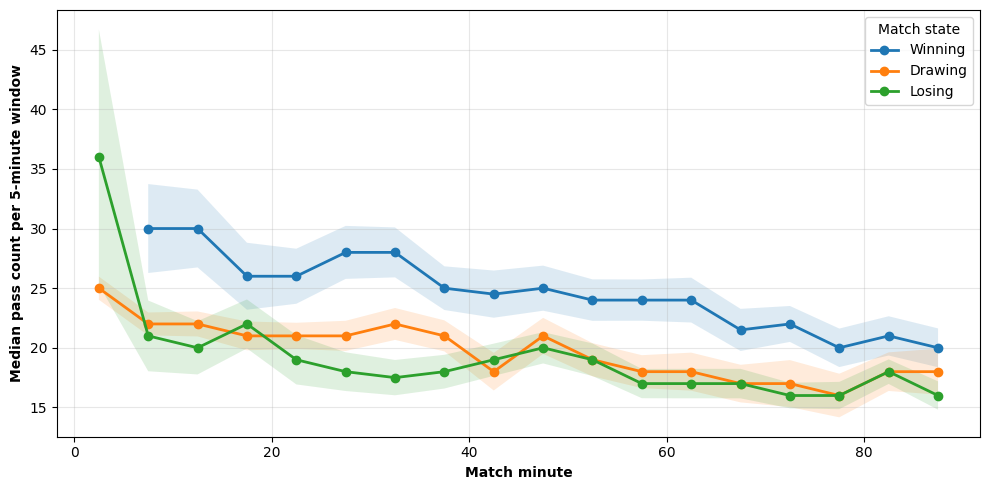

In [43]:
pass_count_time_df = state_metrics_df.copy()

pass_count_time_df = pass_count_time_df[
    pass_count_time_df["window_midpoint_minute"].between(0, 90)
].copy()

pass_count_time_df["time_bin"] = (
    np.floor(pass_count_time_df["window_midpoint_minute"] / 5) * 5
)

pass_count_time_df["time_bin_midpoint"] = pass_count_time_df["time_bin"] + 2.5

pass_count_summary = (
    pass_count_time_df
    .groupby(["time_bin_midpoint", "state"], as_index=False)
    .agg(
        median_pass_count=("pass_count", "median"),
        n=("pass_count", "size"),
        sd=("pass_count", "std")
    )
)

pass_count_summary["sem"] = pass_count_summary["sd"] / np.sqrt(pass_count_summary["n"])
pass_count_summary["ci95"] = 1.96 * pass_count_summary["sem"]

plt.figure(figsize=(10, 5))

for state in state_order:
    state_df = (
        pass_count_summary[pass_count_summary["state"] == state]
        .sort_values("time_bin_midpoint")
    )

    x = state_df["time_bin_midpoint"].to_numpy()
    y = state_df["median_pass_count"].to_numpy()
    ci = state_df["ci95"].to_numpy()

    plt.plot(x, y, marker="o", linewidth=2, label=state.capitalize())
    plt.fill_between(x, y - ci, y + ci, alpha=0.15)

plt.xlabel("Match minute", fontweight="bold")
plt.ylabel("Median pass count per 5-minute window", fontweight="bold")
plt.legend(title="Match state")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/pass_count_over_match_time_by_state.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
pass_count_kruskal_df = run_kruskal_tests(
    agg_df,
    ["pass_count"],
    p_adjust="bonferroni"
)

pass_count_dunn_df = run_dunn_pairwise_tests(
    agg_df,
    ["pass_count"],
    p_adjust="bonferroni"
)

pass_count_kruskal_df.to_csv(
    "tables/pass_count_kruskal_test.csv",
    index=False
)

pass_count_dunn_df.to_csv(
    "tables/pass_count_dunn_pairwise_tests.csv",
    index=False
)

In [40]:
pass_count_kruskal_df

,Metric,Winning median,Drawing median,Losing median,Kruskal statistic,Raw p-value,Corrected p-value
0,pass_count,23.0,22.0,18.416667,56.987686,4.219697e-13,4.219697e-13


In [41]:
pass_count_dunn_df

,Metric,State A,State B,A median,B median,Corrected p-value,Cliff's delta
2,pass_count,drawing,losing,22.0,18.416667,8.197230e-12,0.285000
0,pass_count,winning,drawing,23.0,22.000000,1.000000e+00,0.013065
1,pass_count,winning,losing,23.0,18.416667,8.067182e-10,0.272961


In [ ]:
plt.figure(figsize=(10, 5))

for state in state_order:
    state_df = (
        agg_df[agg_df["state"] == state]
        .sort_values("time_bin_midpoint")
    )

    x = state_df["time_bin_midpoint"].to_numpy()
    y = state_df["mean_pass_count"].to_numpy()
    ci = state_df["ci95"].to_numpy()

    plt.plot(x, y, marker="o", linewidth=2, label=state.capitalize())
    plt.fill_between(x, y - ci, y + ci, alpha=0.15)

plt.xlabel("Match minute", fontweight="bold")
plt.ylabel("Mean pass count per 5-minute window", fontweight="bold")
plt.legend(title="Match state")
plt.grid(alpha=0.3)
plt.tight_layout()

# plt.savefig(
#     "figures/pass_count_over_match_time_by_state.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()

## Regression Analysis

In [48]:
regression_df = agg_df.copy()

regression_df["state"] = pd.Categorical(
    regression_df["state"],
    categories=["losing", "winning", "drawing"],
    ordered=False
)

metrics_for_regression = [
    "density",
    "reciprocity",
    "clustering_coef",
    "median_inter_event_time",
]

def run_pass_count_control_models(df, metrics):
    rows = []

    for metric in metrics:
        model_df = df.dropna(subset=[metric, "state", "pass_count"]).copy()

        model_df["pass_count_z"] = (
            model_df["pass_count"] - model_df["pass_count"].mean()
        ) / model_df["pass_count"].std()

        formula = f"{metric} ~ C(state) + pass_count_z"

        model = smf.ols(
            formula=formula,
            data=model_df
        ).fit(cov_type="HC3")

        for term in model.params.index:
            if term == "Intercept":
                continue

            rows.append({
                "Metric": metric,
                "Term": term,
                "Coefficient": model.params[term],
                "Std error": model.bse[term],
                "t-value": model.tvalues[term],
                "Raw p-value": model.pvalues[term],
                "R2": model.rsquared
            })

    results_df = pd.DataFrame(rows)

    _, corrected_p, _, _ = multipletests(
        results_df["Raw p-value"],
        method="bonferroni"
    )

    results_df["Corrected p-value"] = corrected_p

    return results_df


pass_count_control_results = run_pass_count_control_models(
    regression_df,
    metrics_for_regression
)

pass_count_control_results["Predictor"] = (
    pass_count_control_results["Term"]
    .replace({
        "C(state)[T.winning]": "Winning vs losing",
        "C(state)[T.drawing]": "Drawing vs losing",
        "pass_count_z": "Pass count"
    })
)

pass_count_control_results = pass_count_control_results[
    [
        "Metric",
        "Predictor",
        "Coefficient",
        "Std error",
        "t-value",
        "Raw p-value",
        "Corrected p-value",
        "R2"
    ]
]

pass_count_control_results["Metric"] = (
    pass_count_control_results["Metric"]
    .astype(str)
    .str.replace("_", " ", regex=False)
)

pass_count_control_results = pass_count_control_results.sort_values(
    ["Metric", "Predictor"]
)

pass_count_control_results.to_csv("tables/pass_count_control_results.csv", index=False)
pass_count_control_results

,Metric,Predictor,Coefficient,Std error,t-value,Raw p-value,Corrected p-value,R2
7,clustering coef,Drawing vs losing,0.001159,0.004312,0.268860,7.880372e-01,1.000000e+00,0.643783
8,clustering coef,Pass count,0.082621,0.002186,37.787713,0.000000e+00,0.000000e+00,0.643783
6,clustering coef,Winning vs losing,-0.002539,0.005085,-0.499219,6.176252e-01,1.000000e+00,0.643783
1,density,Drawing vs losing,0.000853,0.001506,0.566296,5.711927e-01,1.000000e+00,0.732251
2,density,Pass count,0.034279,0.000781,43.885240,0.000000e+00,0.000000e+00,0.732251
0,density,Winning vs losing,0.003980,0.001735,2.293381,2.182607e-02,2.619128e-01,0.732251
10,median inter event time,Drawing vs losing,834.684049,331.377678,2.518830,1.177455e-02,1.412946e-01,0.286860
11,median inter event time,Pass count,-2896.032331,196.071688,-14.770273,2.277889e-49,2.733467e-48,0.286860
9,median inter event time,Winning vs losing,1198.450107,398.904402,3.004354,2.661453e-03,3.193744e-02,0.286860
4,reciprocity,Drawing vs losing,-0.002427,0.004999,-0.485391,6.273990e-01,1.000000e+00,0.581819
